# Airline Delay Prediction and Operational Optimization

**Student:** Dilip Kumar Balu  
**University:** Bellevue University  
**Course:** DSC 680 – Applied Data Science  
**Milestone:** 2 – Draft White Paper and Code

**Prof.: Xu Ashton**

## GitHub Repository

The project dataset, documentation, and source code are available at:

https://github.com/DilipKumar95/Dilip-Data-Science-Portfolio/tree/main/Airline%20Delay%20Prediction%20and%20Operational%20Optimization

## Reproducibility

The analysis uses `airline_sample_150k.csv`, a sample of
150,000 flight records from 2009–2020.

Download the dataset from the GitHub repository and place it
in the directory expected by the notebook before running the code.

**Research questions:** (1) Can scheduling and route data predict arrival delays ≥15 minutes? (2) How much does knowing departure delay improve prediction? (3) Which factors correlate with delays? (4) How accurately can we estimate arrival-delay minutes?

**Important data audit:** The uploaded 2020 rows have a column alignment problem (e.g. `ARR_DELAY` contains clock-time-like values and `CANCELLED` contains taxi-like durations). They are **quarantined, not modeled**. The 2019 file has no scheduled-departure fields, so the predeparture model uses 2009–2018 and the departure-informed model uses 2009–2019. The 2020 data must be re-exported with correct column alignment before a pandemic comparison can be made. Results apply to sampled, noncancelled flights with observed arrival outcomes, not all scheduled flights.

The sample contains 12,500 flights per year; annual averages are **not flight-volume weighted**. Train/validation/test periods are chronological. No information recorded after the prediction point is used as a feature.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
    mean_absolute_error, mean_squared_error)

DATA = Path('airline_sample_150k.csv')
if not DATA.exists(): DATA = Path('/mnt/data/airline_sample_150k.csv')
assert DATA.exists(), 'Place airline_sample_150k.csv beside this notebook.'
FIG = Path('figures'); FIG.mkdir(exist_ok=True)
df = pd.read_csv(DATA, low_memory=False)
print('Raw rows:',len(df),'Columns:',len(df.columns))
print(df.groupby('YEAR').size().to_string())

Raw rows: 150000 Columns: 31
YEAR
2009    12500
2010    12500
2011    12500
2012    12500
2013    12500
2014    12500
2015    12500
2016    12500
2017    12500
2018    12500
2019    12500
2020    12500


## Cleaning, schema reconciliation and data dictionary
Key fields: `FL_DATE` = flight date; `OP_CARRIER`/`OP_UNIQUE_CARRIER` = carrier ID; `ORIGIN`, `DEST` = airports; `CRS_DEP_TIME` = scheduled departure HHMM; `DISTANCE` = route miles; `DEP_DELAY` = departure delay in minutes; `ARR_DELAY` = arrival delay in minutes; `CANCELLED`, `DIVERTED` = flight outcome flags. **Target:** `ARR_DELAY >= 15` (industry-style threshold). Negative delay minutes indicate early arrival. Missing outcome rows were already excluded by the sampling script; the analysis cannot estimate cancellation risk.

**Reproducible preparation:** remove exact duplicates; quarantine 2020 schema-misaligned rows; coalesce carrier codes; convert numeric fields; exclude flagged cancellations/diversions when flags are trustworthy; impute missing predictors *inside training pipelines only*. Do not use `ARR_TIME`, taxi-in, airtime, delay causes or other post-arrival variables as predictors.

In [2]:
print('Missing values for key fields by year:')
print(df.groupby('YEAR')[['CRS_DEP_TIME','DISTANCE','OP_CARRIER','OP_UNIQUE_CARRIER','DEP_DELAY']].apply(lambda x:x.isna().sum()).to_string())
print('Exact duplicates:', df.duplicated().sum())
df = df.drop_duplicates().copy()
quarantined_2020 = df[df['YEAR']==2020].copy()
print('Quarantined 2020 rows:',len(quarantined_2020))
df = df[df.YEAR.between(2009,2019)].copy()
df['CARRIER'] = df['OP_CARRIER'].fillna(df['OP_UNIQUE_CARRIER'])
df['FL_DATE'] = pd.to_datetime(df['FL_DATE'],errors='coerce')
for c in ['ARR_DELAY','DEP_DELAY','DISTANCE','CRS_DEP_TIME','CANCELLED','DIVERTED']:
    df[c] = pd.to_numeric(df[c],errors='coerce')
# 2019 cancellation/diversion fields are absent; those records have known arrival outcomes.
df = df[(df['CANCELLED'].fillna(0)==0) & (df['DIVERTED'].fillna(0)==0)]
df = df.dropna(subset=['FL_DATE','ARR_DELAY','CARRIER','ORIGIN','DEST'])
df['MONTH'] = df.FL_DATE.dt.month
df['DAY_OF_WEEK'] = df.FL_DATE.dt.dayofweek
df['SCHED_HOUR'] = np.floor(df['CRS_DEP_TIME']/100).where(lambda s:s.between(0,23))
df['DELAYED'] = (df.ARR_DELAY>=15).astype(int)
print('Usable 2009–2019 rows:',len(df),'delay prevalence:',round(df.DELAYED.mean(),3))
print(df.groupby('YEAR').agg(n=('DELAYED','size'),delay_rate=('DELAYED','mean')).round(3).to_string())

Missing values for key fields by year:
      CRS_DEP_TIME  DISTANCE  OP_CARRIER  OP_UNIQUE_CARRIER  DEP_DELAY
YEAR                                                                  
2009             0         0           0              12500          0
2010             0         0           0              12500          0
2011             0         0           0              12500          0
2012             0         0           0              12500          0
2013             0         0           0              12500          0
2014             0         0           0              12500          0
2015             0         0           0              12500          0
2016             0         0           0              12500          0
2017             0         0           0              12500          0
2018             0         0           0              12500          7
2019         12500         0       12500                  0          0
2020          1228     12500          

## Exploratory analysis
The five illustrations below are generated from the actual sample; carrier comparisons are descriptive associations, not causal rankings. The 2019 scheduled-hour field is absent, so time-of-day plots exclude 2019.

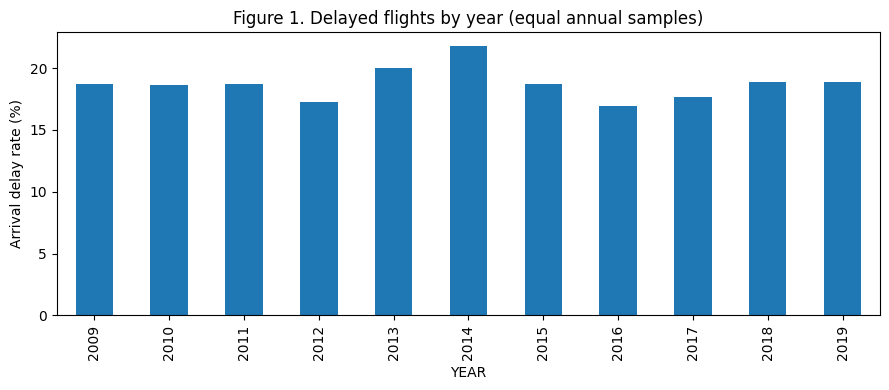

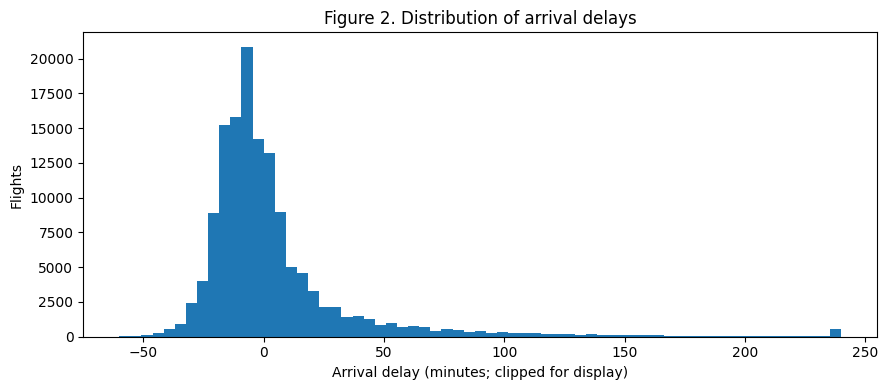

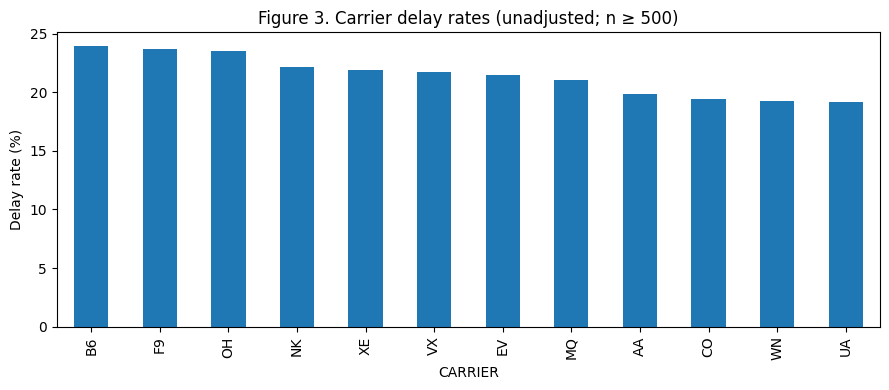

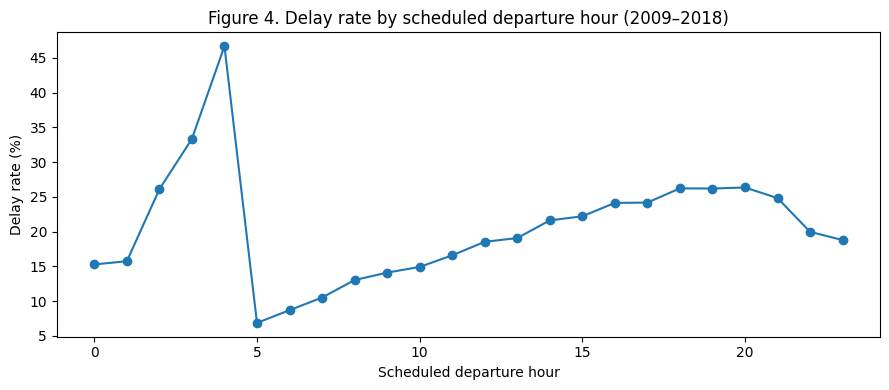

In [3]:
year = df.groupby('YEAR').DELAYED.mean()*100
fig,ax=plt.subplots(figsize=(9,4));year.plot.bar(ax=ax);ax.set(ylabel='Arrival delay rate (%)',title='Figure 1. Delayed flights by year (equal annual samples)');plt.tight_layout();fig.savefig(FIG/'01_delay_by_year.png',dpi=160);plt.show()
fig,ax=plt.subplots(figsize=(9,4));ax.hist(df.ARR_DELAY.clip(-60,240),bins=65);ax.set(xlabel='Arrival delay (minutes; clipped for display)',ylabel='Flights',title='Figure 2. Distribution of arrival delays');plt.tight_layout();fig.savefig(FIG/'02_delay_distribution.png',dpi=160);plt.show()
carrier = df.groupby('CARRIER').agg(n=('DELAYED','size'),rate=('DELAYED','mean')).query('n >= 500').sort_values('rate',ascending=False).head(12)
fig,ax=plt.subplots(figsize=(9,4));(carrier.rate*100).plot.bar(ax=ax);ax.set(ylabel='Delay rate (%)',title='Figure 3. Carrier delay rates (unadjusted; n ≥ 500)');plt.tight_layout();fig.savefig(FIG/'03_carrier_rates.png',dpi=160);plt.show()
hr = df.dropna(subset=['SCHED_HOUR']).groupby('SCHED_HOUR').DELAYED.mean()*100
fig,ax=plt.subplots(figsize=(9,4));hr.plot(ax=ax,marker='o');ax.set(xlabel='Scheduled departure hour',ylabel='Delay rate (%)',title='Figure 4. Delay rate by scheduled departure hour (2009–2018)');plt.tight_layout();fig.savefig(FIG/'04_hourly_rates.png',dpi=160);plt.show()

## Modeling and validation
**Predeparture:** scheduled hour, date, carrier, airports and distance. **Departure-informed:** date, carrier, airports, distance and departure-delay minutes. No scheduled hour in the second model because 2019 lacks it. Logistic regression provides an interpretable baseline; random forest captures nonlinear interactions. A majority-class baseline is reported to avoid misleading accuracy claims. Thresholds are selected on the validation year to maximize F1; the test year is untouched during selection. Random splits are avoided to reduce future-to-past leakage. Carrier and airport identity can still encode historical operational conditions and must not be interpreted as causal.

In [4]:
def model_data(mode):
    if mode=='predeparture':
        d=df[df.YEAR<=2018].dropna(subset=['SCHED_HOUR']).copy()
        cols=['CARRIER','ORIGIN','DEST','DISTANCE','MONTH','DAY_OF_WEEK','SCHED_HOUR']
        tr=d.YEAR<=2016; va=d.YEAR==2017; te=d.YEAR==2018
    else:
        d=df.dropna(subset=['DEP_DELAY']).copy()
        cols=['CARRIER','ORIGIN','DEST','DISTANCE','MONTH','DAY_OF_WEEK','DEP_DELAY']
        tr=d.YEAR<=2017; va=d.YEAR==2018; te=d.YEAR==2019
    return d,cols,tr,va,te

def preprocessing(cols):
    cat=['CARRIER','ORIGIN','DEST'];num=[x for x in cols if x not in cat]
    return ColumnTransformer([
        ('num',Pipeline([('fill',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num),
        ('cat',Pipeline([('fill',SimpleImputer(strategy='most_frequent')),
                         ('encode',OneHotEncoder(handle_unknown='ignore'))]),cat)])

def scores(y,pred,prob):
    return dict(accuracy=accuracy_score(y,pred),precision=precision_score(y,pred,zero_division=0),
      recall=recall_score(y,pred,zero_division=0),f1=f1_score(y,pred,zero_division=0),
      roc_auc=roc_auc_score(y,prob),pr_auc=average_precision_score(y,prob))

results=[]; fitted={}
for mode in ['predeparture','departure_informed']:
    d,cols,tr,va,te=model_data(mode)
    X=d[cols];y=d.DELAYED
    for name,est in [('Logistic regression',LogisticRegression(max_iter=500,class_weight='balanced')),
                     ('Random forest',RandomForestClassifier(n_estimators=60,max_depth=14,
                           min_samples_leaf=8,class_weight='balanced_subsample',random_state=42,n_jobs=-1))]:
        pipe=Pipeline([('prep',preprocessing(cols)),('model',est)])
        pipe.fit(X.loc[tr],y.loc[tr]); vp=pipe.predict_proba(X.loc[va])[:,1]
        thresholds=np.arange(.15,.81,.05)
        threshold=max(thresholds,key=lambda t:f1_score(y.loc[va],vp>=t,zero_division=0))
        tp=pipe.predict_proba(X.loc[te])[:,1]; pred=(tp>=threshold).astype(int)
        result=dict(scenario=mode,model=name,train_n=int(tr.sum()),validation_n=int(va.sum()),test_n=int(te.sum()),threshold=round(float(threshold),2),**scores(y.loc[te],pred,tp))
        results.append(result);fitted[(mode,name)]=(pipe,y.loc[te],pred,tp)
    baseline=np.zeros(int(te.sum()),dtype=int)
    results.append(dict(scenario=mode,model='Always on time',train_n=int(tr.sum()),validation_n=int(va.sum()),test_n=int(te.sum()),threshold=np.nan,**scores(y.loc[te],baseline,np.repeat(y.loc[tr].mean(),int(te.sum())))))
metrics=pd.DataFrame(results)
print(metrics.round(3).to_string(index=False))
metrics.to_csv('classification_metrics.csv',index=False)

          scenario               model  train_n  validation_n  test_n  threshold  accuracy  precision  recall    f1  roc_auc  pr_auc
      predeparture Logistic regression    99992         12500   12500        0.5     0.584      0.248   0.590 0.349    0.620   0.263
      predeparture       Random forest    99992         12500   12500        0.5     0.557      0.249   0.664 0.362    0.628   0.272
      predeparture      Always on time    99992         12500   12500        NaN     0.811      0.000   0.000 0.000    0.500   0.189
departure_informed Logistic regression   112492         12493   12500        0.8     0.934      0.881   0.755 0.813    0.933   0.879
departure_informed       Random forest   112492         12493   12500        0.5     0.924      0.793   0.807 0.800    0.915   0.813
departure_informed      Always on time   112492         12493   12500        NaN     0.811      0.000   0.000 0.000    0.500   0.189


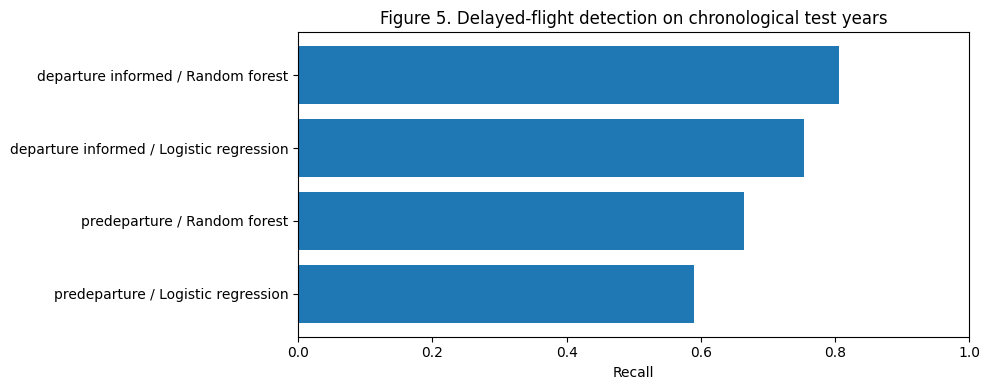

predeparture confusion matrix (rows actual 0/1, cols predicted 0/1):
 [[5904 4235]
 [ 967 1394]]
departure_informed confusion matrix (rows actual 0/1, cols predicted 0/1):
 [[9901  240]
 [ 579 1780]]


In [5]:
fig,ax=plt.subplots(figsize=(10,4));subset=metrics[metrics.model!='Always on time'];labels=subset.scenario.str.replace('_',' ')+' / '+subset.model
ax.barh(labels,subset['recall']);ax.set(xlabel='Recall',xlim=(0,1),title='Figure 5. Delayed-flight detection on chronological test years');plt.tight_layout();fig.savefig(FIG/'05_model_recall.png',dpi=160);plt.show()
for mode in ['predeparture','departure_informed']:
    pipe,y,pred,prob=fitted[(mode,'Logistic regression')]
    print(mode,'confusion matrix (rows actual 0/1, cols predicted 0/1):\n',confusion_matrix(y,pred))

## Arrival-delay regression
Predict arrival-delay minutes from departure-informed features with Ridge regression, compared against the training-period mean. Evaluate on 2019, using MAE and RMSE. The result is a forecasting estimate, not a guarantee of operational savings.

In [6]:
d,cols,tr,va,te=model_data('departure_informed')
reg=Pipeline([('prep',preprocessing(cols)),('model',Ridge(alpha=10,solver="lsqr"))])
reg.fit(d.loc[tr,cols],d.loc[tr,'ARR_DELAY'])
y=d.loc[te,'ARR_DELAY'];pred=reg.predict(d.loc[te,cols]);base=np.full(len(y),d.loc[tr,'ARR_DELAY'].mean())
regression=pd.DataFrame([{'model':name,'MAE_minutes':mean_absolute_error(y,p),
'RMSE_minutes':np.sqrt(mean_squared_error(y,p))} for name,p in [('Training mean',base),('Ridge regression',pred)]])
print(regression.round(2).to_string(index=False));regression.to_csv('regression_metrics.csv',index=False)

           model  MAE_minutes  RMSE_minutes
   Training mean        24.74         50.43
Ridge regression         9.53         13.49


## Assumptions, limitations, ethics and implementation
- **Selection bias (high likelihood, medium impact):** Only flights with observed arrival delays were sampled; cancellation and diversion risk cannot be estimated. Mitigate by describing the target population explicitly and separately modeling cancellations in future work.
- **Schema validity (high likelihood, high impact):** 2020 rows are misaligned and 2019 lacks schedule fields. Mitigate by quarantining 2020, using model-specific periods, and checking upstream schema before reintroduction.
- **Fairness (medium likelihood, high impact):** Carrier and airport comparisons reflect routes, weather and operating environments. Do not penalize operators based on unadjusted comparisons; audit performance by group and route.
- **Overreliance (medium likelihood, high impact):** False positives and missed delays may misallocate resources. Use human review, calibrated alerts and monitoring; no autonomous dispatch decisions.
- **Privacy (low likelihood, low impact):** Dataset contains flight operations rather than passenger identifiers; verify upstream terms and avoid linking to identifiable personnel.
- **Transformations and presentation:** `DELAYED` is defined as ≥15 minutes; 2020 is excluded; the 2019 schedule gap limits comparability; chart display clipping is labeled. The sample is equal-sized per year, not proportional to total flight volumes. Historical association does not imply causality.
- **Regulatory and provenance:** Confirm the Kaggle dataset's original source and license before publishing. FAA/DOT reporting definitions are useful context; this analysis is not an FAA-certified operational safety system.

**Implementation proposal:** (1) validate a current, schema-consistent dataset, (2) benchmark on newer holdout months, (3) test alert thresholds with operations staff, (4) pilot a human-reviewed dashboard, (5) monitor recall, precision, calibration, subgroup performance and drift, and (6) expand only after evidence of benefit.

**Challenges:** Schema drift, missing scheduled fields, sample selection, class imbalance and distribution shift. **Future uses:** weather integration, calibrated probabilities, route-adjusted comparisons, and independent 2020/postpandemic analysis.

**References (starting points to verify and format in APA paper):** U.S. Bureau of Transportation Statistics, Airline On-Time Performance Data; Federal Aviation Administration, Aviation System Performance Metrics; Kaggle, Airline Delay Analysis (sherrytp).

## Appendix: reproducibility and ten anticipated audience questions
**Reproduce:** Place the sampled CSV alongside the notebook; install `pandas numpy matplotlib scikit-learn`; run cells in order. Outputs: `figures/*.png`, `classification_metrics.csv`, `regression_metrics.csv`. Recreate the sample from the original yearly files using the previously provided seeded reservoir sampler; retain the 2020 quarantine and document all filters.

1. Why define a delay as at least 15 minutes?
2. Why exclude 2020?
3. Why does 2019 lack scheduled departure time?
4. How representative is the equal-year sample?
5. How many cancellations were omitted?
6. What information is available at each prediction point?
7. Why use chronological validation instead of random splitting?
8. How does recall compare with precision and the majority baseline?
9. Could carrier comparisons unfairly penalize certain airlines?
10. How would a real-world pilot measure operational improvement?